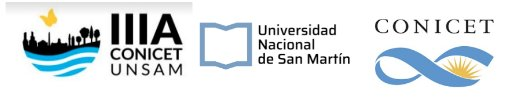  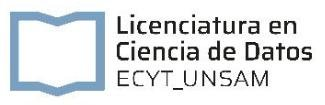

---

# NB10 — Estadística espacial en retícula: autocorrelación y clústeres

Lo que veremos en esta notebook:

- [x] Datos areales: la primera ley de la geografía hecha análisis
- [x] Matrices de pesos espaciales: contigüidad y distancias
- [x] Índice de Moran global: autocorrelación escalar
- [x] LISA y clústeres locales: descomposición espacial del Moran
- [x] Getis-Ord Gi*: detección de hotspots y coldspots
- [x] Moran bivariado: asociaciones entre variables en el espacio
- [x] Revisión del MAUP con datos de la escala natural
---

### Objetivos de la notebook

Al terminar esta clase esperamos que puedas:

- Construir y diagnosticar matrices de pesos espaciales (contigüidad Queen/Rook, k-vecinos, distance band).
- Calcular el índice de Moran global con significancia por permutación.
- Identificar clústeres espaciales locales con LISA y distinguir HH, LL, HL, LH.
- Aplicar Getis-Ord Gi* y leer la diferencia con LISA.
- Diseñar un análisis bivariado entre NBI y ΔNDVI pensado para responder nuestra pregunta integradora.

### Datos con los que trabajaremos

- `../data/proc/radios_con_stats_espectrales.gpkg` — radios del Censo 2022 con estadísticas de NDVI 2026 (de la integración raster-vectorial).
- `../data/raw_data/satelital/S2_AMBANO_B02B03B04B08_2015ago.tif` — imagen 2015 para calcular ΔNDVI por radio.

### Conexión con el arco del curso

Esta notebook es una de las ramas de la estadística espacial — la que formaliza el análisis de **datos areales** (los radios censales). Donde antes vimos eventos puntuales (RENABAP), acá tratamos la geografía como una variable continua sobre polígonos. El giro conceptual respecto a las clases anteriores: hasta acá cada píxel o cada radio fue tratado como independiente. Desde ahora, **la geografía es parte del modelo**. Vamos a formalizar la primera ley de la geografía (Tobler, 1970): *"Todo está relacionado con todo, pero las cosas cercanas están más relacionadas que las distantes"*.

Los productos de esta clase alimentan la regresión espacial integradora del final del curso: los clústeres de vulnerabilidad y las variables espacialmente autocorrelacionadas son insumos centrales del modelo que cruza vulnerabilidad social con cambio de cobertura.

---
# 0. Bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio

from libpysal.weights import Queen, Rook, KNN, DistanceBand, Kernel
from esda.moran import Moran, Moran_Local, Moran_BV, Moran_Local_BV
from esda.getisord import G_Local
from splot.esda import moran_scatterplot, plot_local_autocorrelation, lisa_cluster

from ade_tools import estadisticas_zonales

PROC = '../data/proc/'
RAW  = '../data/raw_data/'
OUT  = '../data/out/'

FN_RADIOS   = PROC + 'radios_con_stats_espectrales.gpkg'

---
# 1. La primera ley de la geografía

Tobler escribió en 1970: *"Everything is related to everything else, but near things are more related than distant things."*

Una declaración a primera vista trivial, pero con consecuencias metodológicas profundas:

- **Rompe la independencia.** Los métodos estadísticos clásicos (OLS, tests t) asumen observaciones independientes. Si las observaciones están geográficamente correlacionadas, los errores estándar clásicos están subestimados: los tests rechazan más de la cuenta, los p-valores no son confiables.

- **Es informativa.** Saber cuán rápido decrece la correlación con la distancia caracteriza el proceso espacial subyacente. Una variable que se mantiene correlacionada a 10 km habla de procesos de gran escala (geopolítica, mercado laboral); una que se des-correlaciona en 500 m habla de procesos locales (diseño urbano, microclima).

- **Habilita predicción.** El kriging —que vemos en NB13 opcional— es un estimador basado enteramente en la autocorrelación espacial.

La **autocorrelación espacial** es la formalización cuantitativa. En esta notebook la medimos con el índice de Moran y sus variantes.

---
# 2. Preparación: ΔNDVI temporalmente comparable por radio

Para el análisis vamos a necesitar una variable ambiental por radio que refleje **cambio temporal** de la cobertura vegetal. Siguiendo el diseño temporal del curso (3 imágenes: 2015 ago, 2025 ago, 2026 feb), la comparación **limpia de estacionalidad** es ago 2015 vs ago 2025 — dos inviernos separados por una década. Esa es la que vamos a construir y usar.

Si querés retomar la comparación feb 2026 vs ago 2015 (que mezcla cambio con fenología), el valor es también informativo por otras razones: permite leer "cuánto verde hay en febrero respecto a hace 10 años en invierno", que es una firma del estado del ciclo anual. La tratamos como variable complementaria más adelante.

In [ ]:
# Construimos ambos NDVIs (2015 y 2025) de forma homogénea
import os
from ade_tools import guardar_geotiff

def construir_ndvi(fn_img_s2, fn_ndvi_out, nombre_banda):
    """Construye NDVI desde imagen S2 B02B03B04B08. Idempotente."""
    if os.path.exists(fn_ndvi_out):
        print(f'Ya existe: {fn_ndvi_out}')
        return
    with rasterio.open(fn_img_s2) as src:
        im = src.read().astype(float)
        perfil = src.profile.copy()
    ESC = 10_000.0
    OFFSET = -1_000.0                    # BOA_ADD_OFFSET: ambas fechas lo tienen (NB02 §3)
    valido = np.all(im != 0, axis=0)     # sobre el DN crudo, antes del offset
    rojo = (im[2] + OFFSET) / ESC
    nir  = (im[3] + OFFSET) / ESC
    ndvi = np.where(valido & ((nir+rojo) != 0), (nir-rojo)/(nir+rojo), np.nan).astype(np.float32)
    guardar_geotiff(fn_ndvi_out, ndvi, perfil, nodata=np.nan,
                    nombres_bandas=[nombre_banda])

construir_ndvi(RAW + 'satelital/S2_AMBANO_B02B03B04B08_2015ago.tif',
                PROC + 'ndvi_completo_2015ago.tif', 'NDVI_2015ago')
construir_ndvi(RAW + 'satelital/S2_AMBANO_B02B03B04B08_2025ago.tif',
                PROC + 'ndvi_completo_2025ago.tif', 'NDVI_2025ago')

In [ ]:
# Zonal stats de ambas fechas
gdf = gpd.read_file(FN_RADIOS)
with rasterio.open(PROC + 'ndvi_completo_2015ago.tif') as src:
    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

stats_2015 = estadisticas_zonales(PROC + 'ndvi_completo_2015ago.tif', gdf,
                                   stats=('median',), banda=1)
stats_2025 = estadisticas_zonales(PROC + 'ndvi_completo_2025ago.tif', gdf,
                                   stats=('median',), banda=1)
stats_2015.columns = ['ndvi_mediana_2015']
stats_2025.columns = ['ndvi_mediana_2025']
gdf = gdf.join(stats_2015).join(stats_2025)

# ΔNDVI temporal LIMPIO: ago vs ago (misma estación, 10 años de diferencia)
gdf['delta_ndvi'] = gdf['ndvi_mediana_2025'] - gdf['ndvi_mediana_2015']

print(f'Radios: {len(gdf)}')
print(f'\nΔNDVI (ago 2025 - ago 2015):')
print(gdf['delta_ndvi'].describe())

---
# 3. Matrices de pesos espaciales

Una **matriz de pesos espaciales** $W$ es el objeto matemático que codifica la vecindad: $w_{ij}$ es el peso de $j$ como vecino de $i$ (con $w_{ii} = 0$). Las elecciones habituales:

| Criterio | Definición |
|---|---|
| **Queen** | Comparten borde O vértice. Generoso. |
| **Rook** | Comparten borde. Más restrictivo que Queen. |
| **K-Nearest Neighbors** | Los $k$ más cercanos por centroide. Cada polígono tiene exactamente $k$ vecinos. |
| **Distance Band** | Todos los polígonos a menos de $d$ metros. Dispersos en zonas rurales. |
| **Kernel** | Decaimiento suave con la distancia. Más realista pero computacionalmente pesado. |

La elección no es inocua: distintas $W$ pueden dar conclusiones distintas sobre autocorrelación. En áreas urbanas compactas, Queen y Rook dan resultados parecidos; en áreas rurales con radios grandes e irregulares, pueden divergir. Una buena práctica es **reportar al menos dos matrices y verificar que la conclusión se mantenga**.

Para este curso usamos Queen como baseline. La documentación de `libpysal` cubre los detalles y casos límite.

In [ ]:
# Matriz Queen
w = Queen.from_dataframe(gdf, use_index=False)
w.transform = 'r'   # row-standardization: cada fila suma 1

print(f'Radios: {w.n}')
print(f'Conexiones promedio: {w.mean_neighbors:.2f}')
print(f'Radios sin vecinos (islands): {len(w.islands)}')
if len(w.islands) > 0:
    print('  ATENCIÓN: hay polígonos aislados — los tests de autocorrelación los excluyen automáticamente.')

In [ ]:
# Histograma del número de vecinos: diagnóstico de la forma de la retícula
neighbors_count = pd.Series([len(w.neighbors[i]) for i in w.neighbors])
fig, ax = plt.subplots(figsize=(8, 4))
neighbors_count.value_counts().sort_index().plot(kind='bar', color='steelblue', ax=ax)
ax.set_xlabel('Número de vecinos Queen'); ax.set_ylabel('Cantidad de radios')
ax.set_title(f'Distribución del número de vecinos (media = {neighbors_count.mean():.1f})')
plt.tight_layout(); plt.show()

---
# 4. Índice de Moran global

Para una variable $x$ con media $\bar{x}$:

$$I = \frac{n}{\sum_{i,j} w_{ij}} \cdot \frac{\sum_{i,j} w_{ij}(x_i - \bar{x})(x_j - \bar{x})}{\sum_i (x_i - \bar{x})^2}$$

Interpretación:

- $I$ cerca del valor esperado $-1/(n-1)$: ausencia de autocorrelación espacial.
- $I > -1/(n-1)$: **autocorrelación positiva** (valores similares juntos — clusters).
- $I < -1/(n-1)$: **autocorrelación negativa** (valores opuestos adyacentes — tablero de ajedrez, raro en la práctica).

**Significancia**: por permutaciones de Monte Carlo. Se reetiqueta la variable $x$ aleatoriamente entre los polígonos, se calcula $I$ para cada permutación, y se compara con el $I$ observado. `esda` implementa 999 permutaciones por defecto.

> **Qué testea exactamente.** El test de permutación asume **intercambiabilidad**: bajo la hipótesis nula, el valor $x_i$ no depende de la ubicación de $i$. No está testeando "CSR" ni que los datos sean iid: permuta los valores sobre las mismas localizaciones. En la práctica es lo que queremos, pero es bueno no confundirlo con "los datos son independientes".

Referencia canónica: Cliff & Ord (1981) *Spatial Processes*. Moran publicó el índice en 1950 pero la formalización rigurosa para datos georreferenciados vino después.

In [ ]:
# Moran global de NBI y de ΔNDVI — excluimos radios con NaN en vez de rellenar
# con 0 (rellenar sesgaría el índice hacia "no cambio" y contaminaría el test).
mask_validos = gdf['delta_ndvi'].notna() & gdf['nbi_pct'].notna()
gdf_m = gdf[mask_validos].copy()

# Reconstruimos W sobre el subconjunto válido (estructura topológica muy similar
# salvo por algunas islas aisladas que puedan emerger al filtrar)
w_m = Queen.from_dataframe(gdf_m, use_index=False)
w_m.transform = 'r'

y_nbi   = gdf_m['nbi_pct'].values
y_dndvi = gdf_m['delta_ndvi'].values

mi_nbi   = Moran(y_nbi,   w_m, permutations=999)
mi_dndvi = Moran(y_dndvi, w_m, permutations=999)

print(f'Radios con datos completos: {len(gdf_m)} / {len(gdf)}')
print('\nMoran global:')
print(f'  NBI %  : I = {mi_nbi.I:+.4f}   EI = {mi_nbi.EI:+.4f}   p = {mi_nbi.p_sim:.4f}')
print(f'  ΔNDVI  : I = {mi_dndvi.I:+.4f}   EI = {mi_dndvi.EI:+.4f}   p = {mi_dndvi.p_sim:.4f}')

In [ ]:
# Moran scatter plot del NBI
fig, ax = plt.subplots(figsize=(8, 7))
moran_scatterplot(mi_nbi, zstandard=True, ax=ax)   # plot_moran no acepta ax: arma su propia figura
ax.set_title(f'Moran scatter plot — NBI %   (I = {mi_nbi.I:.3f})')
plt.tight_layout()
plt.show()

El Moran scatter plot grafica $x_i$ estandarizado vs el **retardo espacial** $\sum_j w_{ij} x_j$ (la variable promedio de los vecinos). La pendiente de la regresión de uno sobre el otro es exactamente $I$. Los cuatro cuadrantes del plot se interpretan como:

| Cuadrante | Significado |
|---|---|
| HH (arriba a la derecha) | Valor alto rodeado de valores altos |
| LL (abajo a la izquierda) | Valor bajo rodeado de valores bajos |
| HL (abajo a la derecha) | Valor alto rodeado de valores bajos (anomalía positiva local) |
| LH (arriba a la izquierda) | Valor bajo rodeado de valores altos (anomalía negativa local) |

Esta decomposición es la base del LISA.

---
# 5. LISA: autocorrelación local

Anselin (1995) definió los **Local Indicators of Spatial Association (LISA)**: una descomposición del Moran global en una contribución por radio:

$$I_i = z_i \sum_j w_{ij} z_j, \quad z_i = \frac{x_i - \bar{x}}{s_x}$$

La suma de todos los $I_i$ es proporcional al $I$ global. Cada $I_i$ tiene significancia propia (pseudo-p-valor por permutaciones condicionales) y cae en uno de los 4 cuadrantes del Moran scatter plot.

Para visualizar, se suele hacer un **mapa LISA** donde los radios se colorean por cuadrante **solo si su autocorrelación local es significativa** (típicamente $p < 0.05$). Los radios significativos HH son **hotspots**; los LL, **coldspots**; los HL y LH son **spatial outliers**.

**Cuidado con los tests múltiples.** Estamos haciendo un test por cada radio —miles de tests simultáneos—. Bajo la hipótesis nula se espera que el 5% de los radios sean "significativos" por azar. Con 2000 radios serían 100 falsos positivos. La corrección estándar es **Benjamini-Hochberg (FDR)**, que acota la proporción esperada de falsos positivos entre los significativos. Abajo aplicamos la corrección explícitamente y comparamos.

In [ ]:
# LISA del NBI (sobre el subconjunto con datos válidos)
lisa_nbi = Moran_Local(y_nbi, w_m, permutations=999, seed=42)

# Corrección FDR (Benjamini-Hochberg) sobre los pseudo p-valores.
# Ordenamos los p-valores ascendentemente y comparamos el i-ésimo contra
# (i/m) * alpha. El mayor i que cumple la desigualdad define el umbral FDR.
def fdr_threshold(pvals, alpha=0.05):
    m = len(pvals)
    p_ord = np.sort(pvals)
    umbrales = (np.arange(1, m+1) / m) * alpha
    ok = np.where(p_ord <= umbrales)[0]
    return float(p_ord[ok.max()]) if len(ok) > 0 else 0.0

p_fdr = fdr_threshold(lisa_nbi.p_sim, alpha=0.05)
n_sig_naive = (lisa_nbi.p_sim < 0.05).sum()
n_sig_fdr   = (lisa_nbi.p_sim < p_fdr).sum() if p_fdr > 0 else 0
print(f'Radios significativos al 5% sin corrección: {n_sig_naive}')
print(f'Umbral FDR al 5%                           : p < {p_fdr:.4f}')
print(f'Radios significativos post-FDR             : {n_sig_fdr}')

In [ ]:
# Mapa de clusters LISA (con umbral FDR para honestidad estadística)
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
fig.set_facecolor('white')
lisa_cluster(lisa_nbi, gdf_m, p=0.05, ax=axes[0])
axes[0].set_title(f'LISA del NBI %  —  p < 0.05 crudo ({n_sig_naive} radios)')
axes[0].set_axis_off()

lisa_cluster(lisa_nbi, gdf_m, p=p_fdr, ax=axes[1])
axes[1].set_title(f'LISA del NBI %  —  p < FDR ({p_fdr:.3f}, {n_sig_fdr} radios)')
axes[1].set_axis_off()
plt.tight_layout()
plt.show()

In [ ]:
# Guardamos las etiquetas LISA en gdf_m (el frame filtrado).
# Convención pysal: 1=HH, 2=LH, 3=LL, 4=HL
cuadrantes = {1:'HH', 2:'LH', 3:'LL', 4:'HL'}
gdf_m['lisa_nbi_q']     = lisa_nbi.q
gdf_m['lisa_nbi_p']     = lisa_nbi.p_sim
gdf_m['lisa_nbi_sig']   = (lisa_nbi.p_sim < 0.05).astype(int)
gdf_m['lisa_nbi_sigFDR']= (lisa_nbi.p_sim < p_fdr).astype(int)

# Conteo por cuadrante (solo los significativos)
for q, nombre in cuadrantes.items():
    n_total = (lisa_nbi.q == q).sum()
    n_sig = ((lisa_nbi.q == q) & (lisa_nbi.p_sim < 0.05)).sum()
    n_fdr = ((lisa_nbi.q == q) & (lisa_nbi.p_sim < p_fdr)).sum()
    print(f'{nombre}: {n_total:4d} total, {n_sig:4d} al 5%, {n_fdr:4d} post-FDR')

---
# 6. Getis-Ord Gi*

**Gi\*** (Getis & Ord, 1992) es una alternativa a LISA con una interpretación un poco distinta. Mientras LISA pregunta si la autocorrelación local es distinta de cero, Gi\* pregunta si un punto es parte de un clúster de valores altos o bajos **en valor absoluto**:

$$G_i^* = \frac{\sum_j w_{ij}^* x_j}{\sum_j x_j}$$

donde $w_{ij}^*$ incluye al propio $i$ como vecino (la diferencia con el $G_i$ original).

Gi\* no distingue HL/LH — no identifica outliers espaciales. Pero es la herramienta estándar para identificar **hotspots de concentración** de valores altos (o coldspots de valores bajos), y por eso es muy usada en epidemiología, criminología, y planificación.

Una lectura práctica: **LISA te dice dónde el valor es atípico respecto a sus vecinos; Gi\* te dice dónde se concentran los valores altos o bajos.** Ambas informaciones son complementarias.

In [ ]:
# Gi* del NBI (usa el mismo subconjunto filtrado)
g_nbi = G_Local(y_nbi, w_m, star=True, permutations=999, seed=42)

# El estadístico Gi* se estandariza: valores > 1.96 son hotspots significativos al 5%
gdf_m['gi_star_z'] = g_nbi.Zs
gdf_m['gi_star_p'] = g_nbi.p_sim
gdf_m['gi_hotspot'] = np.where(g_nbi.Zs > 1.96, 'hotspot',
                      np.where(g_nbi.Zs < -1.96, 'coldspot', 'no significativo'))

fig, ax = plt.subplots(figsize=(12, 10))
colores_gi = {'hotspot':'#d62728','coldspot':'#1f77b4','no significativo':'#eeeeee'}
for cat, color in colores_gi.items():
    gdf_m[gdf_m['gi_hotspot'] == cat].plot(ax=ax, color=color, edgecolor='gray',
                                            linewidth=0.1, label=cat)
ax.legend(loc='lower left')
ax.set_title('Getis-Ord Gi* del NBI % — hotspots y coldspots (p < 0.05)', fontsize=12)
ax.set_axis_off()
plt.tight_layout()
plt.show()

---
# 7. Moran bivariado: NBI versus ΔNDVI

El Moran bivariado (Anselin et al., 2002, *Spatial Analysis of ESDA*) extiende el análisis a dos variables $x, y$:

$$I_{xy} = \frac{n}{\sum_{i,j} w_{ij}} \cdot \frac{\sum_{i,j} w_{ij}\, z^x_i\, z^y_j}{\sum_i (z^x_i)^2}$$

donde los $z^x, z^y$ son las versiones estandarizadas de $x$ e $y$. Con $W$ *row-standardized* ($\sum_{i,j} w_{ij} = n$), esto simplifica a:

$$I_{xy} = \frac{z_x^T\, W\, z_y}{z_x^T\, z_x}$$

**Qué mide.** El numerador es el producto de $z^x_i$ por el retardo espacial de $y$ en el vecindario de $i$. El denominador normaliza por la dispersión de $x$. En otras palabras: ¿el valor de $x$ en $i$ covaria con el promedio de $y$ en sus vecinos?

Note que el denominador es $\sum_i (z^x_i)^2$, **no** la covarianza entre $x$ e $y$ — ese sería $z_x^T z_y$. Esta distinción no es trivial: si invirtiéramos los argumentos y calculáramos $I_{yx}$ el resultado sería diferente, porque el denominador cambia. Es por eso que en la nota de asimetría que sigue aclaramos qué variable "centra" el análisis.

> **Asimetría importante.** `Moran_BV(x, y, w)` mide si $x_i$ se asocia al **retardo espacial de $y$**. La pregunta no es simétrica: "vulnerabilidad en el centro, pérdida vegetal en los vecinos" no es la misma pregunta que "pérdida vegetal en el centro, vulnerabilidad en los vecinos". Según cuál pongas primero, estás modelando una relación distinta.

En nuestro caso: ¿los radios con alto NBI están rodeados de zonas con caída de cobertura vegetal (ΔNDVI negativo)? Si sí, hay evidencia espacial de acoplamiento entre vulnerabilidad social y degradación ambiental. Esta es la formalización geoestadística de la pregunta sobre acoplamiento entre vulnerabilidad social y degradación ambiental.

In [ ]:
# Moran bivariado entre NBI (variable x) y ΔNDVI (variable y en vecinos)
mi_bv = Moran_BV(y_nbi, y_dndvi, w_m, permutations=999)
print(f'Moran bivariado NBI × ΔNDVI_vecinos: I = {mi_bv.I:+.4f}   p = {mi_bv.p_sim:.4f}')

# LISA bivariado: identifica radios donde la asociación es espacialmente significativa
lisa_bv = Moran_Local_BV(y_nbi, y_dndvi, w_m, permutations=499, seed=42)

fig, ax = plt.subplots(figsize=(12, 10))
lisa_cluster(lisa_bv, gdf_m, p=0.05, ax=ax)
ax.set_title(f'LISA bivariado — NBI × ΔNDVI vecino   (I_BV global = {mi_bv.I:.3f})', fontsize=12)
ax.set_axis_off()
plt.tight_layout()
plt.show()

El signo y la magnitud del Moran bivariado global dan una primera respuesta a nuestra pregunta integradora. Los mapas LISA bivariados localizan **dónde** está el acoplamiento: los cuadrantes HH en el mapa bivariado son los radios donde el NBI es alto Y el ΔNDVI de sus vecinos es alto (es decir, zonas que ganaron vegetación — podría ser obras de urbanización o arborización; o errores de la variable).

**Más adelante:** vamos a volver a usar esta estructura. El modelo de regresión espacial integradora va a formalizar esta asociación bivariada en un marco en el que podemos controlar por otras variables (densidad, vivienda precaria, etc.).

---
# 8. Guardado del producto

In [ ]:
cols_out = ['cod_radio','nbi_pct','viv_precaria_pct','densidad_pob','iv',
            'ndvi_mediana','ndvi_mediana_2015','ndvi_mediana_2025','delta_ndvi',
            'lisa_nbi_q','lisa_nbi_p','lisa_nbi_sig',
            'gi_star_z','gi_star_p','gi_hotspot',
            'geometry']
gdf_m[cols_out].to_file(PROC + 'radios_con_lisa_gi.gpkg', driver='GPKG')
print(f'Guardado: {PROC}radios_con_lisa_gi.gpkg  ({len(gdf_m)} radios con datos completos)')

---
# 9. Exploración interactiva con Folium

Los mapas estáticos de matplotlib son perfectos para publicaciones, pero para **explorar** los resultados —identificar un radio puntual, comparar su NBI con sus vecinos, navegar por el territorio— un mapa interactivo es mucho más efectivo.

`folium` genera mapas web basados en Leaflet.js. El output es un archivo HTML: se puede abrir en cualquier navegador, compartir por correo, o embeberlo en un informe. Las capas son navegables, con zoom y popups al clicar.

En este contexto vamos a construir un mapa con los resultados del LISA y los hotspots Gi*, donde cada radio tiene un popup con sus atributos clave. Es el tipo de producto que se le entrega a un municipio o a una secretaría de política pública.

In [ ]:
try:
    import folium
    from folium import Choropleth, GeoJsonTooltip, GeoJson
    from folium.plugins import Fullscreen
    FOLIUM_OK = True
except ImportError:
    FOLIUM_OK = False
    print('folium no está instalado. pip install folium')

if FOLIUM_OK:
    # Folium trabaja en WGS84 (EPSG:4326)
    gdf_wgs = gdf_m.to_crs('EPSG:4326')

    # Centro del mapa
    lat_c = gdf_wgs.geometry.centroid.y.mean()
    lon_c = gdf_wgs.geometry.centroid.x.mean()

    m = folium.Map(location=[lat_c, lon_c], zoom_start=11,
                   tiles='CartoDB positron')
    Fullscreen().add_to(m)

    # ── Capa 1: NBI % (choropleth continuo) ──────────────────────────
    Choropleth(
        geo_data=gdf_wgs.__geo_interface__,
        data=gdf_wgs,
        columns=['cod_radio', 'nbi_pct'],
        key_on='feature.properties.cod_radio',
        fill_color='YlOrRd',
        fill_opacity=0.65,
        line_opacity=0.1,
        legend_name='NBI %',
        name='NBI %',
        show=True,
    ).add_to(m)

    # ── Capa 2: Clusters LISA (HH/LL/HL/LH + no significativo) ───────
    colors_lisa = {
        'HH': '#d62728',   # rojo — alto rodeado de alto
        'LL': '#1f77b4',   # azul — bajo rodeado de bajo
        'HL': '#ff7f0e',   # naranja — alto rodeado de bajo (outlier positivo)
        'LH': '#9467bd',   # violeta — bajo rodeado de alto (outlier negativo)
        'ns': '#eeeeee',   # gris — no significativo
    }
    cuad_map = {1:'HH', 2:'LH', 3:'LL', 4:'HL'}

    def style_lisa(feature):
        q_code = feature['properties'].get('lisa_nbi_q', 0)
        sig    = feature['properties'].get('lisa_nbi_sig', 0)
        q_name = cuad_map.get(q_code, 'ns') if sig == 1 else 'ns'
        return {
            'fillColor': colors_lisa[q_name],
            'color': 'gray',
            'weight': 0.3,
            'fillOpacity': 0.75,
        }

    # Construimos el dict de propiedades que queremos en el popup
    cols_popup = ['cod_radio', 'nbi_pct', 'densidad_pob', 'iv',
                  'delta_ndvi', 'gi_hotspot', 'lisa_nbi_q', 'lisa_nbi_sig']
    # Solo incluimos columnas que existen en gdf_m
    cols_popup = [c for c in cols_popup if c in gdf_wgs.columns]

    GeoJson(
        gdf_wgs[cols_popup + ['geometry']],
        name='Clusters LISA (NBI)',
        style_function=style_lisa,
        tooltip=GeoJsonTooltip(
            fields=cols_popup,
            aliases=['Radio', 'NBI %', 'Densidad (hab/ha)', 'Índice Vuln.',
                     'ΔNDVI', 'Gi* hotspot', 'Cuadrante LISA', 'Sig LISA'],
            localize=True,
            sticky=False,
            labels=True,
            style='font-size: 12px; padding: 4px;',
        ),
        show=True,
    ).add_to(m)

    # ── Capa 3: Hotspots Gi* ─────────────────────────────────────────
    def style_gistar(feature):
        tipo = feature['properties'].get('gi_hotspot', 'no significativo')
        fill = {'hotspot':'#d62728', 'coldspot':'#1f77b4'}.get(tipo, 'none')
        return {
            'fillColor': fill,
            'color': 'none',
            'weight': 0,
            'fillOpacity': 0.6 if tipo != 'no significativo' else 0,
        }

    if 'gi_hotspot' in gdf_wgs.columns:
        GeoJson(
            gdf_wgs[['gi_hotspot', 'gi_star_z', 'cod_radio', 'geometry']],
            name='Hotspots Gi* (NBI)',
            style_function=style_gistar,
            show=False,   # apagada por defecto; el usuario la activa
        ).add_to(m)

    folium.LayerControl(collapsed=False).add_to(m)

    fn_mapa = OUT + 'mapa_interactivo_lisa.html'
    m.save(fn_mapa)
    print(f'Mapa guardado: {fn_mapa}')
    print('Abrilo en un navegador o cargalo en JupyterLab con:')
    print('  from IPython.display import IFrame')
    print('  IFrame(src=fn_mapa, width=900, height=550)')

In [ ]:
# Para verlo embebido en el notebook (solo si el servidor lo permite):
if FOLIUM_OK:
    from IPython.display import IFrame, display
    display(IFrame(src=fn_mapa, width='100%', height=550))

**Capas del mapa:**
- **NBI %** (choropleth): muestra la distribución por radio, coloreado como en los mapas estáticos.
- **Clusters LISA**: coloreado por cuadrante HH/LL/HL/LH (solo radios significativos); no significativos aparecen en gris. Activá el tooltip cliqueando un radio para ver todos los atributos.
- **Hotspots Gi\*** (desactivada por defecto): polígonos coloreados solo donde hay hotspot o coldspot significativo.

Para publicar el HTML: es un archivo autocontenido sin dependencias externas, podés enviarlo por email o subirlo a cualquier servidor web. Para proyectos de largo plazo, `folium` permite guardar en formatos estáticos (PNG) vía herramientas de captura de pantalla de Chromium, o exportar la geometría a aplicaciones como Kepler.gl.

---
# Ejercicios de entrega

---

## Ejercicio 1 — ΔNDVI estacional como complemento

En la sección 2 usamos ΔNDVI ago-ago, temporalmente limpio. La alternativa ΔNDVI feb 2026 − ago 2015 es interesante por otras razones: captura la diferencia entre **fin de verano 2026 y fin de invierno 2015**, que es una firma del contraste estacional moderno versus el de hace una década.

a) Calculá ese ΔNDVI estacional y agregalo como columna nueva (`delta_ndvi_estacional`).

b) Reportá el Moran global de esta variable. ¿Cambia respecto al ΔNDVI limpio?

c) Discutí en 3-4 oraciones qué interpretación tiene cada versión de ΔNDVI — no "una es correcta y la otra no", sino qué pregunta responde cada una.

---

## Ejercicio 2 — Sensibilidad a la matriz W

a) Repetí el análisis del Moran global del NBI con tres matrices de pesos: Queen, KNN con $k=5$, y DistanceBand con $d = 2000$ m.

b) Para cada una, calculá el promedio de vecinos y la cantidad de islas.

c) ¿Cambian las conclusiones sobre autocorrelación? ¿Qué matriz recomendarías y por qué?

---

## Ejercicio 3 — Hotspots de vulnerabilidad acoplados con caída vegetal

Usando los resultados:

a) Identificá los radios que son **simultáneamente** hotspot de NBI (Gi* > 1.96) Y con ΔNDVI por debajo del percentil 25 (caída grande de vegetación).

b) Hacé un mapa que destaque esos radios y los otros en gris.

c) Describí en 1 párrafo dónde se ubican esos radios en el territorio (partido, zona) y qué implicancia tiene para políticas públicas: son zonas donde se acumulan vulnerabilidad social y degradación ambiental.

---

## Ejercicio 4 — Convergencia con procesos de puntos (NB07)

En NB07 analizamos los asentamientos del RENABAP como proceso de puntos: identificamos zonas de agregación y su relación con cauces. Ahora tenemos los hotspots Gi\* del NBI por radio. Los dos objetos —densidad de asentamientos y hotspots de NBI— miden cosas relacionadas pero distintas: uno es eventos discretos, otro es una variable areal continua.

a) Contá cuántos centroides de RENABAP caen dentro de radios hotspot Gi\* (Z > 1.96). Compará con una nula: si los RENABAP estuvieran distribuidos al azar entre los radios ponderando por área, ¿cuántos caerían? (basta con `n_renabap × área_hotspots / área_total`).

b) Si el conteo observado supera claramente el esperado, eso es evidencia de **convergencia metodológica**: dos enfoques distintos (procesos de puntos y estadística areal) detectan el mismo fenómeno de vulnerabilidad territorial.

c) Identificá al menos un radio hotspot Gi\* **sin** RENABAP registrado. ¿Qué podría explicarlo? Dos hipótesis: (i) el RENABAP está incompleto; (ii) el NBI alto no proviene de asentamientos precarios sino de otras formas de vulnerabilidad.

---

## Ejercicio opcional — Corrección de tests múltiples

Al calcular LISA sobre miles de radios hacemos miles de tests. Aun bajo la nula, ~5% da falsos positivos por azar — con 2000 radios, eso son 100 falsos hotspots.

a) Aplicá corrección **FDR Benjamini-Hochberg** a los p-valores del LISA.

b) Compará el mapa corregido con el crudo. ¿Cuántos hotspots sobreviven?

c) Discutí la tensión entre no rechazar las verdaderas alarmas (power) y no sobreinterpretar ruido (FDR).

*Punteros:* Anselin (1995) LISA; Getis & Ord (1992) estadísticos G; Openshaw & Taylor (1979) MAUP; Cliff & Ord (1981); Castro & Singer (2006) sobre ajuste de tests múltiples en LISA.

---
# Apéndice — Estado de `ade_tools.py` al final de esta clase

Tanto `esda` como `libpysal` proveen las funciones clave. No agregamos nada a `ade_tools.py`. La biblioteca del curso mantiene:

- `escalar, componer_rgb, ecualizar_rgb` (NB01)
- `guardar_geotiff` (NB02)
- `estadisticas_zonales, extraer_pixeles_por_roi` (NB04)
- `jeffries_matusita` (NB05)
